In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/drive/MyDrive/colab/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [9]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
pd.to_numeric(df['TotalCharges'], errors='coerce').isnull().sum()

np.int64(11)

In [12]:
df[pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [13]:
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
for col in df.select_dtypes(include='object').columns:
    if col != 'customerID':
        print(col, df[col].unique())

gender ['Female' 'Male']
SeniorCitizen ['No' 'Yes']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Churn ['No' 'Yes']


In [16]:
pd.crosstab(df['InternetService'], df['OnlineSecurity'])

OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0


In [17]:
pd.crosstab(df['PhoneService'], df['MultipleLines'])

MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,682,0
Yes,3390,0,2971


In [18]:
pd.to_numeric(df['TotalCharges'], errors='coerce').isnull().sum()

np.int64(11)

In [19]:
df[pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [20]:
cols_to_fix = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
               'TechSupport', 'StreamingTV', 'StreamingMovies']

df[cols_to_fix] = df[cols_to_fix].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

In [21]:
mask = pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()
print(mask.sum())
df[mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [22]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [23]:
df.to_csv('/content/drive/MyDrive/colab/telco_clean.csv', index=False)

###EDA

In [24]:
df = pd.read_csv('/content/drive/MyDrive/colab/telco_clean.csv')

In [25]:
(df.groupby('Contract')['Churn']
   .apply(lambda x: (x == 'Yes').mean() * 100)
   .round(1))

,Churn
Contract,
Month-to-month,42.7
One year,11.3
Two year,2.8


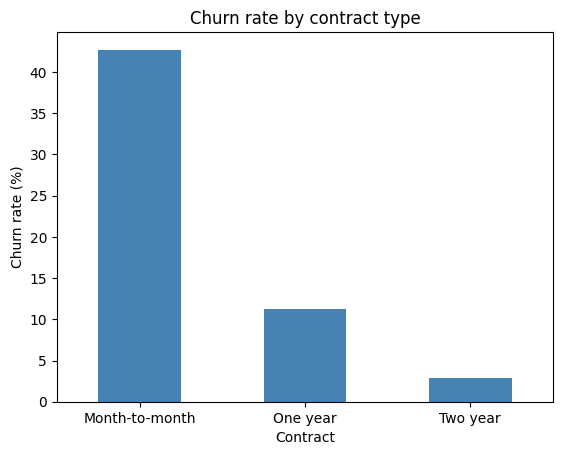

In [26]:
rates = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
rates.plot(kind='bar', color='steelblue')
plt.ylabel('Churn rate (%)')
plt.title('Churn rate by contract type')
plt.xticks(rotation=0)
plt.show()

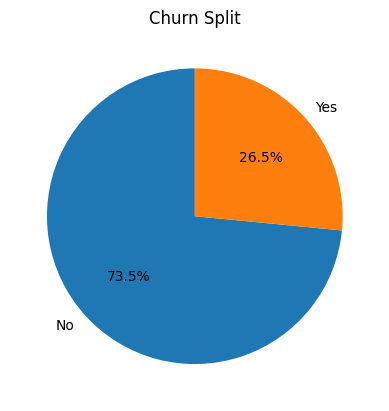

In [27]:
churn_split = df['Churn'].value_counts(normalize=True) * 100
churn_split.plot(
    kind='pie', autopct='%1.1f%%',startangle=90
)

plt.ylabel('')
plt.title('Churn Split')
plt.show()

In [28]:
def churn_rate_by(col, data=df, rotation=0):
    rates = data.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
    print(rates.round(1))
    rates.plot(kind='bar', color='steelblue')
    plt.ylabel('Churn rate (%)')
    plt.title(f'Churn rate by {col}')
    plt.xticks(rotation=rotation)
    plt.show()


InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64


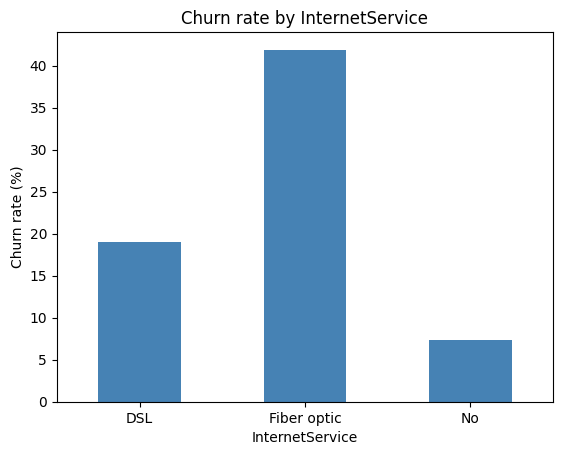

In [29]:
churn_rate_by('InternetService')


PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn, dtype: float64


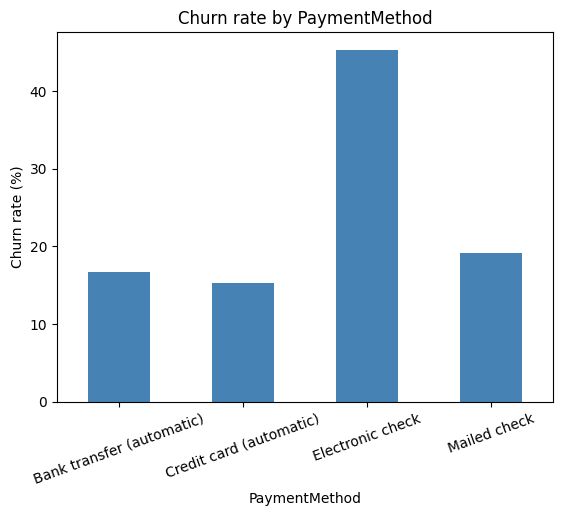

In [30]:
churn_rate_by('PaymentMethod', rotation=20)

TechSupport
No     41.6
Yes    15.2
Name: Churn, dtype: float64


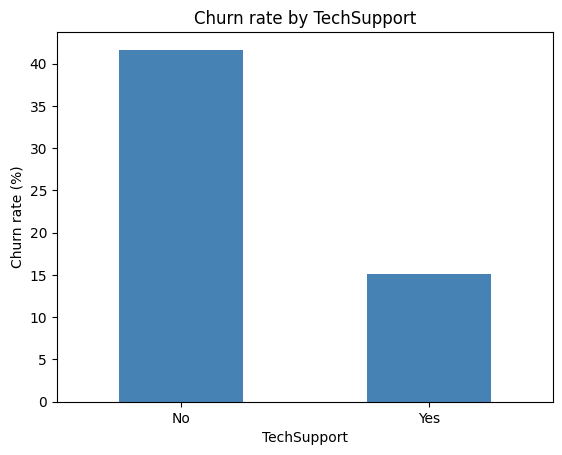

In [31]:
internet_users = df[df['InternetService'] != 'No']
churn_rate_by('TechSupport', data=internet_users)

In [32]:
df.groupby('InternetService')['MonthlyCharges'].mean().round(2)

,MonthlyCharges
InternetService,
DSL,58.10
Fiber optic,91.50
No,21.08


In [33]:
fiber_dsl = df[df['InternetService'] != 'No']
pd.crosstab(fiber_dsl['InternetService'], fiber_dsl['TechSupport'], normalize='index') * 100

TechSupport,No,Yes
InternetService,,
DSL,51.342420,48.657580
Fiber optic,72.028424,27.971576


In [34]:
df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [35]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


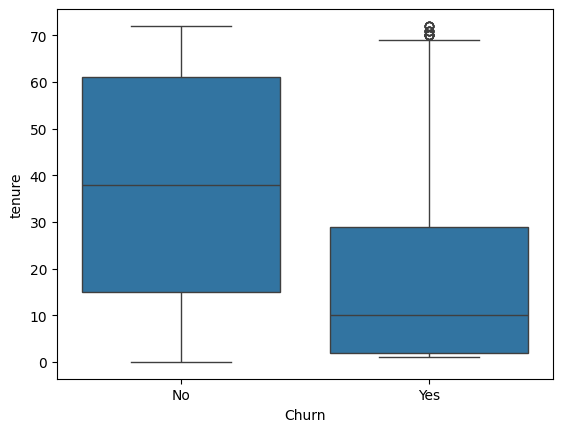

In [36]:
sns.boxplot(x='Churn', y='tenure', data=df)
plt.show()

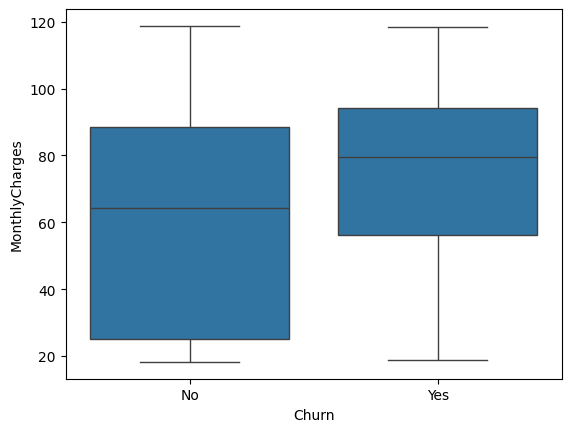

In [37]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.show()

In [38]:
df['Churn_binary'] = df['Churn'].map({'No': 0, 'Yes': 1})
df['Churn_binary'].value_counts()

,count
Churn_binary,
0,5174
1,1869


In [39]:
df['TenureGroup'] = pd.cut(df['tenure'] , bins=[-1,12,24,48,72] , labels = ['0-12','13-24','25-48','49-72'])
df['TenureGroup']

,TenureGroup
0,0-12
1,25-48
2,0-12
3,25-48
4,0-12
...,...
7038,13-24
7039,49-72
7040,0-12
7041,0-12


In [40]:
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies']
df['NumAddons'] = (df[addons] == 'Yes').sum(axis=1)
df['NumAddons']

,NumAddons
0,1
1,2
2,2
3,3
4,0
...,...
7038,5
7039,4
7040,1
7041,0


In [41]:
df['ChurnRiskScore'] = (
    (df['Contract'] == 'Month-to-month') * 2 +
    (df['tenure'] <= 12) * 2 +
    (df['PaymentMethod'] == 'Electronic check') * 1 +
    (df['InternetService'] == 'Fiber optic') * 1 +
    ((df['InternetService'] != 'No') & (df['TechSupport'] == 'No')) * 1
)
df['ChurnRiskScore']

,ChurnRiskScore
0,6
1,1
2,5
3,0
4,7
...,...
7038,0
7039,2
7040,6
7041,6


In [42]:
score_summary = (df.groupby('ChurnRiskScore')['Churn_binary']
                   .agg(customers='count', churn_rate='mean'))
score_summary['churn_rate'] = (score_summary['churn_rate'] * 100).round(1)
print(score_summary)

                customers  churn_rate
ChurnRiskScore                       
0                    1539         2.5
1                     803         7.5
2                     870        11.1
3                     596        19.3
4                    1143        31.1
5                     988        47.1
6                     515        60.6
7                     589        72.3


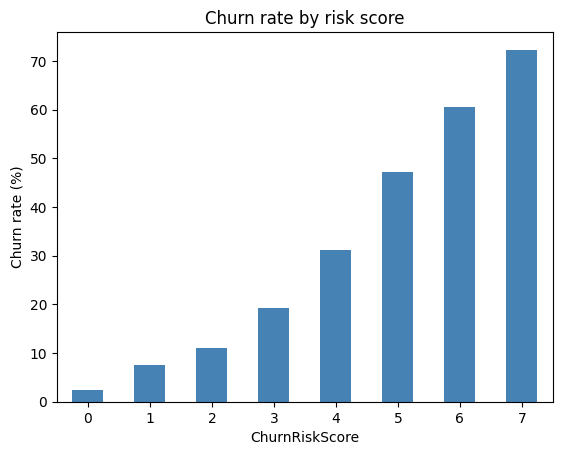

In [43]:
ax = score_summary['churn_rate'].plot(kind='bar', color='steelblue')
ax.set_ylabel('Churn rate (%)')
ax.set_xlabel('ChurnRiskScore')
ax.set_title('Churn rate by risk score')
plt.xticks(rotation=0)
plt.show()

In [44]:
score_summary['churn_rate'].is_monotonic_increasing

True

In [45]:
from scipy.stats import chi2_contingency, mannwhitneyu
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
            'Contract', 'PaperlessBilling', 'PaymentMethod']

In [46]:
results = []
for col in cat_cols:
    ct = pd.crosstab(df[col], df['Churn'])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.sum().sum() * (min(ct.shape) - 1)))
    results.append({'feature': col, 'p_value': p, 'cramers_v': round(v, 3)})
stats_table = pd.DataFrame(results).sort_values('cramers_v', ascending=False)
print(stats_table)

             feature        p_value  cramers_v
13          Contract  5.863038e-258      0.410
6    InternetService  9.571788e-160      0.322
15     PaymentMethod  3.682355e-140      0.303
14  PaperlessBilling   4.073355e-58      0.191
7     OnlineSecurity   1.232098e-46      0.171
10       TechSupport   2.923567e-43      0.164
3         Dependents   4.924922e-43      0.164
1      SeniorCitizen   1.510067e-36      0.150
2            Partner   2.139911e-36      0.150
8       OnlineBackup   6.214093e-12      0.082
9   DeviceProtection   3.315693e-08      0.066
11       StreamingTV   1.302484e-07      0.063
12   StreamingMovies   2.997474e-07      0.061
5      MultipleLines   8.433795e-04      0.040
4       PhoneService   3.387825e-01      0.011
0             gender   4.865787e-01      0.008


In [47]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    stayed = df[df['Churn'] == 'No'][col]
    left = df[df['Churn'] == 'Yes'][col]
    stat, p = mannwhitneyu(stayed, left)
    print(col, f'p = {p:.2e}', '| median stayed:', stayed.median(), '| median left:', left.median())

tenure p = 2.42e-208 | median stayed: 38.0 | median left: 10.0
MonthlyCharges p = 3.31e-54 | median stayed: 64.42500000000001 | median left: 79.65
TotalCharges p = 5.69e-83 | median stayed: 1679.525 | median left: 703.55


In [48]:
df.head(1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary,TenureGroup,NumAddons,ChurnRiskScore
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,...,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12,1,6


In [49]:
drop_cols = ['customerID', 'gender', 'PhoneService',          # no signal / just a label
             'Churn', 'Churn_binary',                         # the target
             'TenureGroup', 'NumAddons', 'ChurnRiskScore']    # derived from other features

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

cat_cols = ['SeniorCitizen', 'Partner', 'Dependents', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod']

In [50]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=drop_cols)
y = df['Churn_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(5634, 17) (1409, 17)
0.265 0.265


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)
print(preprocessor.get_feature_names_out())

(5634, 21) (1409, 21)
['num__tenure' 'num__MonthlyCharges' 'num__TotalCharges'
 'cat__SeniorCitizen_Yes' 'cat__Partner_Yes' 'cat__Dependents_Yes'
 'cat__MultipleLines_Yes' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_Yes' 'cat__StreamingTV_Yes' 'cat__StreamingMovies_Yes'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__PaperlessBilling_Yes' 'cat__PaymentMethod_Credit card (automatic)'
 'cat__PaymentMethod_Electronic check' 'cat__PaymentMethod_Mailed check']


In [52]:
df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr().round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


In [53]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Dummy accuracy:', round(accuracy_score(y_test, dummy.predict(X_test)), 3))

models = {
    'plain':    LogisticRegression(max_iter=1000),
    'balanced': LogisticRegression(max_iter=1000, class_weight='balanced'),
}

fitted = {}
for name, clf in models.items():
    pipe = Pipeline([('prep', clone(preprocessor)), ('model', clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    print(f"{name:9s} accuracy = {accuracy_score(y_test, pred):.3f} | "
          f"predicted churn share = {pred.mean():.3f}")

print(fitted['balanced'].predict_proba(X_test)[:5, 1].round(3))

Dummy accuracy: 0.735
plain     accuracy = 0.806 | predicted churn share = 0.225
balanced  accuracy = 0.738 | predicted churn share = 0.414
[0.117 0.852 0.149 0.657 0.063]


===== plain
              precision    recall  f1-score   support

      Stayed      0.849     0.896     0.872      1035
     Churned      0.659     0.559     0.605       374

    accuracy                          0.806      1409
   macro avg      0.754     0.727     0.738      1409
weighted avg      0.799     0.806     0.801      1409

[[927 108]
 [165 209]]
ROC-AUC: 0.842
===== balanced
              precision    recall  f1-score   support

      Stayed      0.903     0.721     0.802      1035
     Churned      0.504     0.786     0.614       374

    accuracy                          0.738      1409
   macro avg      0.704     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409

[[746 289]
 [ 80 294]]
ROC-AUC: 0.842


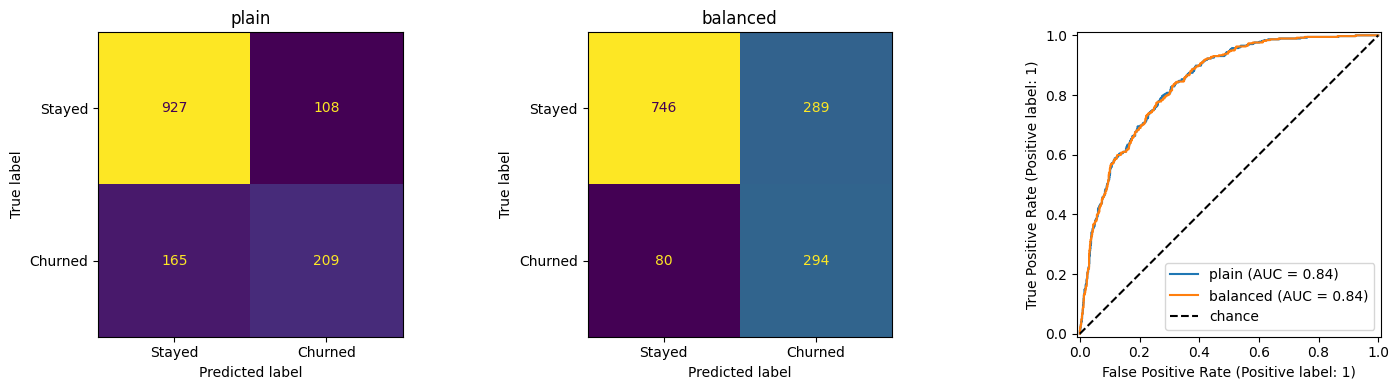

In [54]:
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    print('=====', name)
    print(classification_report(y_test, pred, target_names=['Stayed', 'Churned'], digits=3))
    print(confusion_matrix(y_test, pred))
    print('ROC-AUC:', round(roc_auc_score(y_test, proba), 3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes[:2], fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test,
        display_labels=['Stayed', 'Churned'], ax=ax, colorbar=False)
    ax.set_title(name)
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[2], name=name)
axes[2].plot([0, 1], [0, 1], 'k--', label='chance')
axes[2].legend()
plt.tight_layout()
plt.show()

In [55]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def make_prep(nums):
    return ColumnTransformer([
        ('num', StandardScaler(), nums),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ])

models = {
    'LogReg (balanced)': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           class_weight='balanced', random_state=42, n_jobs=-1),
    'GradBoosting': HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['roc_auc', 'recall', 'precision', 'f1']

rows = []
for name, clf in models.items():
    pipe = Pipeline([('prep', make_prep(num_cols)), ('model', clf)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics, n_jobs=-1)
    rows.append({'model': name,
                 **{m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}" for m in metrics}})
print(pd.DataFrame(rows).to_string(index=False))

            model       roc_auc        recall     precision            f1
LogReg (balanced) 0.846 ± 0.013 0.801 ± 0.036 0.518 ± 0.018 0.629 ± 0.022
     RandomForest 0.843 ± 0.011 0.720 ± 0.040 0.563 ± 0.016 0.632 ± 0.025
     GradBoosting 0.838 ± 0.009 0.525 ± 0.034 0.644 ± 0.029 0.578 ± 0.028


best threshold: 0.16
cost at best threshold: 894978
cost at 0.5: 973808
cost if we do nothing: 1166100


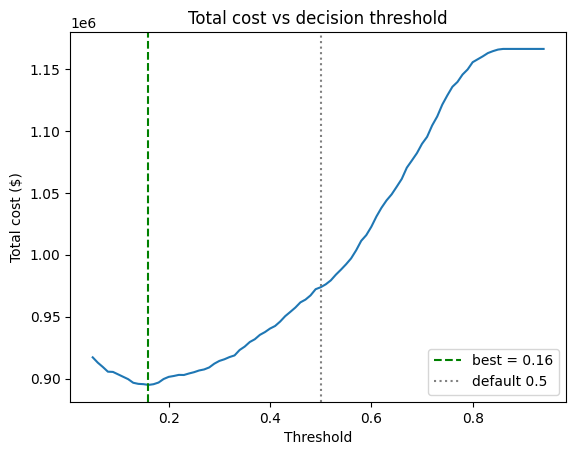

In [56]:
from sklearn.model_selection import cross_val_predict

best_pipe = Pipeline([('prep', make_prep(num_cols)),
                      ('model', LogisticRegression(max_iter=1000))])

oof_proba = cross_val_predict(best_pipe, X_train, y_train, cv=cv,
                              method='predict_proba')[:, 1]

VALUE, OFFER, SUCCESS = 780, 50, 0.4

def total_cost(threshold, y_true, proba, value=VALUE, offer=OFFER, success=SUCCESS):
    pred = (proba >= threshold).astype(int)
    tp = ((pred == 1) & (y_true == 1)).sum()
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    return fp * offer + fn * value + tp * (offer + (1 - success) * value)

y_tr = y_train.values
thresholds = np.arange(0.05, 0.95, 0.01)
costs = [total_cost(t, y_tr, oof_proba) for t in thresholds]
best_t = thresholds[np.argmin(costs)]

do_nothing = y_tr.sum() * VALUE
print('best threshold:', round(best_t, 2))
print('cost at best threshold:', round(min(costs)))
print('cost at 0.5:', round(total_cost(0.5, y_tr, oof_proba)))
print('cost if we do nothing:', round(do_nothing))

plt.plot(thresholds, costs)
plt.axvline(best_t, color='green', linestyle='--', label=f'best = {best_t:.2f}')
plt.axvline(0.5, color='grey', linestyle=':', label='default 0.5')
plt.xlabel('Threshold'); plt.ylabel('Total cost ($)'); plt.legend()
plt.title('Total cost vs decision threshold')
plt.show()

In [57]:
best_pipe.fit(X_train, y_train)
test_proba = best_pipe.predict_proba(X_test)[:, 1]
for t in [0.5, best_t]:
    pred = (test_proba >= t).astype(int)
    print(f'--- threshold {t:.2f}')
    print(classification_report(y_test, pred, target_names=['Stayed', 'Churned'], digits=3))
    print(confusion_matrix(y_test, pred))

--- threshold 0.50
              precision    recall  f1-score   support

      Stayed      0.849     0.896     0.872      1035
     Churned      0.659     0.559     0.605       374

    accuracy                          0.806      1409
   macro avg      0.754     0.727     0.738      1409
weighted avg      0.799     0.806     0.801      1409

[[927 108]
 [165 209]]
--- threshold 0.16
              precision    recall  f1-score   support

      Stayed      0.947     0.590     0.727      1035
     Churned      0.445     0.909     0.598       374

    accuracy                          0.675      1409
   macro avg      0.696     0.750     0.662      1409
weighted avg      0.814     0.675     0.693      1409

[[611 424]
 [ 34 340]]


                                   feature   coef  odds_ratio
                   cat__InternetService_No -1.459       0.233
                    cat__Contract_Two year -1.317       0.268
                               num__tenure -1.256       0.285
                       num__MonthlyCharges -0.764       0.466
                    cat__Contract_One year -0.688       0.503
                   cat__OnlineSecurity_Yes -0.303       0.739
                      cat__TechSupport_Yes -0.253       0.777
                       cat__Dependents_Yes -0.228       0.796
                     cat__OnlineBackup_Yes -0.051       0.951
cat__PaymentMethod_Credit card (automatic) -0.035       0.966
                          cat__Partner_Yes  0.022       1.022
           cat__PaymentMethod_Mailed check  0.066       1.068
                 cat__DeviceProtection_Yes  0.084       1.088
                    cat__SeniorCitizen_Yes  0.148       1.159
                 cat__PaperlessBilling_Yes  0.371       1.450
       c

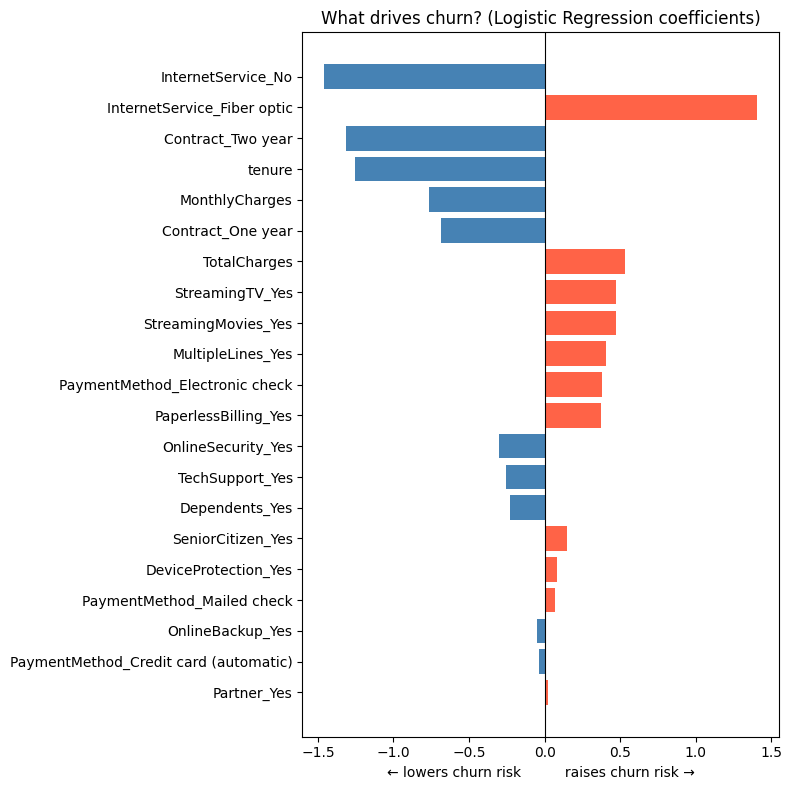

In [58]:
names = best_pipe.named_steps['prep'].get_feature_names_out()
coefs = best_pipe.named_steps['model'].coef_[0]

coef_df = pd.DataFrame({'feature': names, 'coef': coefs, 'odds_ratio': np.exp(coefs)})
coef_df = coef_df.sort_values('coef')
print(coef_df.round(3).to_string(index=False))

plot_df = coef_df.copy()
plot_df['label'] = plot_df['feature'].str.replace('cat__', '').str.replace('num__', '')
plot_df = plot_df.reindex(plot_df['coef'].abs().sort_values().index)
colors = ['tomato' if c > 0 else 'steelblue' for c in plot_df['coef']]

plt.figure(figsize=(8, 8))
plt.barh(plot_df['label'], plot_df['coef'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('← lowers churn risk          raises churn risk →')
plt.title('What drives churn? (Logistic Regression coefficients)')
plt.tight_layout()
plt.show()

In [59]:
from sklearn.model_selection import cross_val_score

variants = {'all 3 numeric': ['tenure', 'MonthlyCharges', 'TotalCharges'],
            'no TotalCharges': ['tenure', 'MonthlyCharges'],
            'tenure only': ['tenure']}

for label, nums in variants.items():
    pipe = Pipeline([('prep', make_prep(nums)),
                     ('model', LogisticRegression(max_iter=1000))])
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    pipe.fit(X_train, y_train)
    names = pipe.named_steps['prep'].get_feature_names_out()
    cf = pd.Series(pipe.named_steps['model'].coef_[0], index=names)
    print(f'{label}: CV AUC {auc.mean():.3f} ± {auc.std():.3f}')
    print(cf[[c for c in cf.index if c.startswith('num__')]].round(2).to_string(), '\n')

all 3 numeric: CV AUC 0.846 ± 0.013
num__tenure           -1.26
num__MonthlyCharges   -0.76
num__TotalCharges      0.53 

no TotalCharges: CV AUC 0.845 ± 0.012
num__tenure           -0.80
num__MonthlyCharges   -0.62 

tenure only: CV AUC 0.844 ± 0.012
num__tenure   -0.79 



In [60]:
num_final = ['tenure', 'MonthlyCharges']
final_pipe = Pipeline([('prep', make_prep(num_final)),
                       ('model', LogisticRegression(max_iter=1000))])

oof = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
thresholds = np.arange(0.05, 0.95, 0.01)
costs = [total_cost(t, y_train.values, oof) for t in thresholds]
final_t = thresholds[np.argmin(costs)]
print('final threshold:', round(final_t, 2))

final_pipe.fit(X_train, y_train)
test_proba = final_pipe.predict_proba(X_test)[:, 1]
pred = (test_proba >= final_t).astype(int)

print(classification_report(y_test, pred, target_names=['Stayed', 'Churned'], digits=3))
print(confusion_matrix(y_test, pred))
print('Test ROC-AUC:', round(roc_auc_score(y_test, test_proba), 3))

cost_model = total_cost(final_t, y_test.values, test_proba)
cost_nothing = y_test.sum() * VALUE
print(f'Cost: ${cost_model:,.0f} vs ${cost_nothing:,.0f} doing nothing '
      f'({(1 - cost_model / cost_nothing) * 100:.1f}% lower)')

names = final_pipe.named_steps['prep'].get_feature_names_out()
coefs = final_pipe.named_steps['model'].coef_[0]
final_coefs = pd.DataFrame({'feature': names, 'coef': coefs,
                            'odds_ratio': np.exp(coefs)}).sort_values('coef')
print(final_coefs.round(3).to_string(index=False))

final threshold: 0.16
              precision    recall  f1-score   support

      Stayed      0.943     0.595     0.730      1035
     Churned      0.446     0.901     0.596       374

    accuracy                          0.676      1409
   macro avg      0.695     0.748     0.663      1409
weighted avg      0.811     0.676     0.694      1409

[[616 419]
 [ 37 337]]
Test ROC-AUC: 0.839
Cost: $224,376 vs $291,720 doing nothing (23.1% lower)
                                   feature   coef  odds_ratio
                   cat__InternetService_No -1.350       0.259
                    cat__Contract_Two year -1.325       0.266
                               num__tenure -0.803       0.448
                    cat__Contract_One year -0.690       0.502
                       num__MonthlyCharges -0.624       0.536
                   cat__OnlineSecurity_Yes -0.289       0.749
                       cat__Dependents_Yes -0.238       0.788
                      cat__TechSupport_Yes -0.236       0

In [61]:
X_all = df.drop(columns=drop_cols)
y_all = df['Churn_binary']

oof_all = cross_val_predict(final_pipe, X_all, y_all, cv=cv, method='predict_proba')[:, 1]

out = df.copy()
out['ChurnProbability'] = oof_all.round(4)
out['Flagged'] = (oof_all >= final_t).astype(int)
out['RiskBand'] = pd.cut(oof_all, bins=[0, final_t, 0.5, 1.0],
                         labels=['Low', 'Medium', 'High'], include_lowest=True)

print(out.groupby('RiskBand', observed=True)['Churn_binary']
         .agg(customers='count', churn_rate='mean').round(3))

drivers = final_coefs.copy()
drivers['label'] = drivers['feature'].str.replace('cat__', '').str.replace('num__', '')

out.to_csv('/content/drive/MyDrive/colab/telco_dashboard_data.csv', index=False)
drivers.to_csv('/content/drive/MyDrive/colab/model_drivers.csv', index=False)

          customers  churn_rate
RiskBand                       
Low            3257       0.057
Medium         2259       0.298
High           1527       0.660
